# Homework 7: Practicing Regression

### Part 1

Let's practice linear regression using a real estate dataset with information on home prices and other attributes like square footage and garage size.

In [11]:
# Import your libraries... 
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# Check out the data... 
df = pd.read_csv('../regressions/data/real_estate_dataset.csv')
len(df)

500

In [3]:
df.head()

,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


Question: What factors explain differences in housing prices, and how well can we predict the price of a house using its characteristics?

Let's start simple with the question... Does house size affect price?

Fill in the blank: \
The independent variable in this analysis is ____square feet_____. The dependent variable is ___price______. \
The regression formula is Price_i​ = β0 ​+ β1​ (Square_Feeti​) + ϵ_i.


In [5]:
# Ok now let's perform the simple linear regression. Write your code below.

model = smf.ols(formula="Price ~ Square_Feet", data=df).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.312
Model:                            OLS   Adj. R-squared:                  0.311
Method:                 Least Squares   F-statistic:                     225.9
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           2.28e-42
Time:                        11:03:42   Log-Likelihood:                -6472.5
No. Observations:                 500   AIC:                         1.295e+04
Df Residuals:                     498   BIC:                         1.296e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept    4.225e+05   1.16e+04     36.552      0.000       4e+05    4.45e+05
Square_Feet   914.6972     60.861     15.029      0.000     795.121    1034.274
==============================================================================
Omnibus:                        4.314   Durbin-Watson:                   2.062
Prob(Omnibus):                  0.116   Jarque-Bera (JB):                3.953
Skew:                           0.157   Prob(JB):                        0.139
Kurtosis:                       2.698   Cond. No.                         483.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

House size (Square_Feet) has a positive and statistically significant relationship with house prices. However, house size alone explains approximately 31.2% of the variation in housing prices.

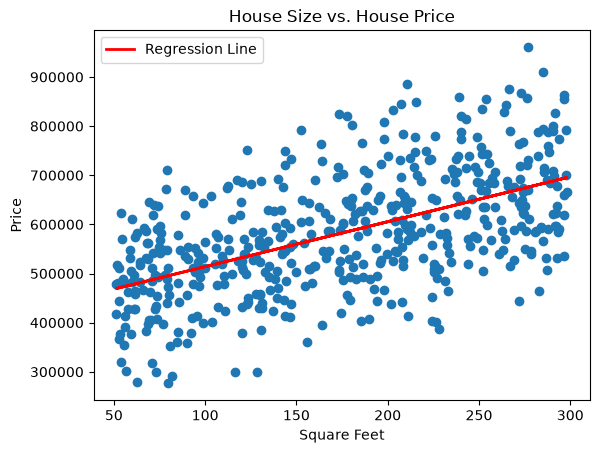

In [9]:
# Plot your data on a scatterplot and draft a regression line. Write your code below.

plt.scatter(df["Square_Feet"], df["Price"])

# Draw the regression line
plt.plot(
    df["Square_Feet"],
    model.predict(),
    color='red',
    linewidth=2,
    label='Regression Line'
)

# Add your labels!
plt.title("House Size vs. House Price")
plt.xlabel("Square Feet")
plt.ylabel("Price")

plt.legend()
plt.show()


Ok, let's take it a step further. Our new question is: Does house size still matter when we control for the number of bedrooms and bathrooms?

Fill in the blank: 

The independent variable in this analysis is ____square feet_____. 

The dependent variable is ____price_____. 

The control variables are ___num_bedrooms and num_bathrooms_____. 

The regression formula is Price ​= β0 ​+ β1​Square_Feet ​+ β2Num_Bedrooms + β3Num_Bathrooms + ϵi + β2​Num_Bedrooms​ + β3​Num_Bathrooms​ + ϵi​. 

I'll help you with the code for the next part.

In [10]:
# Run multiple linear regression
model = smf.ols("Price ~ Square_Feet + Num_Bedrooms + Num_Bathrooms", data=df).fit()

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.700
Model:                            OLS   Adj. R-squared:                  0.698
Method:                 Least Squares   F-statistic:                     385.7
Date:                Sun, 08 Nov 2026   Prob (F-statistic):          3.29e-129
Time:                        11:09:08   Log-Likelihood:                -6265.0
No. Observations:                 500   AIC:                         1.254e+04
Df Residuals:                     496   BIC:                         1.255e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      2.055e+05   1.26e+04     16.270

Fill in the blank: 

Your model explains __70___% of the variation in house prices, and __all___ of my 3 explanatory variables are statistically significant.

When square footage is zero, the predicted house price is __205,500 monetary units___.

For every additional square foot, we can expect the predicted house price to increase by __964.62___ units, on average.


### Part 2

Read the main article in the Tampa Bay Times' Pulitzer Prize-winning series Failure Factories:\
https://projects.tampabay.com/projects/2015/investigations/pinellas-failure-factories/5-schools-segregation/

And then read the criticism of it in Forbes:\
https://www.forbes.com/sites/maureensullivan/2016/04/29/here-are-the-holes-in-the-pulitzer-winning-failure-factories-series-on-segregated-schools/

Answer the following questions (in at least 3 sentences each), which we will discuss further in class:

1. What are your thoughts on the Tampa Bay Times' series? What parts of it do you find valuable to readers?

2. The series got a scathing critique in Forbes. What are your thoughts on the critique? Do you find it compelling? What do you think the journalists at the Florida newsroom should have done differently? 